# 00 — Integration

From a clean clone: config, cache, validators, counts for fafb and malecns (and the hemibrain, used in E6 and step 15), then the Project 5 step 15: the pair sampler and the first discrepancy count. Runs off `data/cache/` with no network I/O once the cache exists (a cold cache downloads the raw files once).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

In [2]:
import logging
import config
from src.fetch_fafb import load_neurons, load_edges, load_edgeroi
from src.validate import validate_dataset
from src.summary import summary
logging.basicConfig(level=logging.INFO, format="%(name)s: %(message)s")
print("FAFB", config.FAFB_MATERIALIZATION, config.FAFB_ANNOTATIONS_TAG, config.FAFB_SYNAPSE_TABLE)

FAFB 783 v3.2.0 buhmann


## Load (cache first) and validate

In [3]:
neurons, edges, edgeroi = load_neurons(), load_edges(), load_edgeroi()
validate_dataset(neurons, edges, edgeroi)
summary(neurons, edges)

src.cache: cache hit: fafb_neurons_783_ann3.2.0.parquet


src.cache: cache hit: fafb_edges_783_buhmann_min1.parquet


src.cache: cache hit: fafb_edgeroi_783_buhmann_min1.parquet


,neurons,edges_min1,edges_min5,edges_min10,synapses,cell_types
dataset,,,,,,
fafb,139262,15091983,2700513,1066822,54492922,8846


## Threshold table (course grid, central brain)

In [4]:
from eda_shared.eda_helpers import add_provisional_flags, relative_weight
import pandas as pd
fl = add_provisional_flags(neurons)
central = set(fl.loc[~fl.is_optic, 'neuron_id'])
e = edges.assign(frac=relative_weight(edges))
e = e[e.pre_id.isin(central) & e.post_id.isin(central)]
rows = []
for label, keep in [(f'>= {t}', e.syn_count >= t) for t in (1, 5, 10, 31)] + \
                   [(f'>= {f:.1%} input', e.frac >= f) for f in (0.009, 0.026)]:
    k = e[keep]
    connected = pd.unique(pd.concat([k.pre_id, k.post_id]))
    rows.append({'criterion': label, 'edges': len(k), 'synapses': int(k.syn_count.sum()),
                 'isolated': len(central) - len(connected),
                 'median_out_degree': float(k.groupby('pre_id').size().median())})
pd.DataFrame(rows)

/home/pc/doktora/CENG8004_Machine_Learning/p5-pu-wiring/eda_shared/eda_helpers.py:86: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["is_optic"] = out["neuropil"].map(table["is_optic"]).fillna(False).astype(bool)


,criterion,edges,synapses,isolated,median_out_degree
0,>= 1,5886895,24883726,315,98.0
1,>= 5,1145235,17318437,1411,15.0
2,>= 10,537059,13378205,4652,6.0
3,>= 31,107536,6442081,21324,2.0
4,>= 0.9% input,1019641,11969747,353,13.0
5,>= 2.6% input,290164,5559983,1512,4.0


## malecns and hemibrain: load and validate

In [5]:
from src import fetch_malecns, fetch_hemibrain
mal = (fetch_malecns.load_neurons(), fetch_malecns.load_edges(), fetch_malecns.load_edgeroi())
validate_dataset(*mal)
hemi = (fetch_hemibrain.load_neurons(), fetch_hemibrain.load_edges(), fetch_hemibrain.load_edgeroi())
validate_dataset(*hemi)
from src.validate import assert_interchangeable
assert_interchangeable(neurons, mal[0]); assert_interchangeable(neurons, hemi[0])
pd.concat([summary(neurons, edges), summary(mal[0], mal[1]), summary(hemi[0], hemi[1])])

src.cache: cache hit: malecns_neurons_v1.0_traced.parquet


src.cache: cache hit: malecns_edges_v1.0_traced_min1_conf0.5.parquet


src.cache: cache hit: malecns_edgeroi_v1.0_traced_min1_conf0.5.parquet


src.cache: cache hit: hemibrain_neurons_v1.2_traced-uncropped.parquet


src.cache: cache hit: hemibrain_edges_v1.2_traced-uncropped_min1.parquet


src.cache: cache hit: hemibrain_edgeroi_v1.2_traced-uncropped_min1.parquet


,neurons,edges_min1,edges_min5,edges_min10,synapses,cell_types
dataset,,,,,,
fafb,139262,15091983,2700513,1066822,54492922,8846
malecns,165122,25563096,6235649,2749394,124024573,11751
hemibrain,21739,3550403,662578,305058,14329229,5554


## Project 5 region: central complex roster

In [6]:
cx = neurons[neurons.cell_class == 'CX']
ids = set(cx.neuron_id)
ecx = edgeroi[edgeroi.neuropil.isin(['EB', 'FB', 'PB', 'NO']) & edgeroi.pre_id.isin(ids) & edgeroi.post_id.isin(ids)]
pair = ecx.groupby(['pre_id', 'post_id']).syn_count.sum()
n = len(ids)
pd.Series({'roster': n, 'ordered pairs': n * (n - 1), 'pairs >= 10': int((pair >= 10).sum()),
           'recorded below 10 (1-9 syn)': int(((pair >= 1) & (pair < 10)).sum())})

roster                            2875
ordered pairs                  8262750
pairs >= 10                      32125
recorded below 10 (1-9 syn)     257763
dtype: int64

## Cross-dataset type mapping and coverage (week 3)

fafb `cell_type` ↔ malecns `flywire_type` only (never the type names), compound values merged into match groups; malecns is its brain part (`src/type_mapping.py`).

In [7]:
from src.eda_e import brain_part
from src.type_mapping import mapping_table, coverage
mal_brain = brain_part(mal[0], mal[1])[0]
tmap = mapping_table(neurons, mal_brain)
overall, by_region = coverage(neurons, mal_brain, tmap)
tmap.to_csv(ROOT / 'reports' / 'type_mapping_fafb_malecns.csv')
by_region.to_csv(ROOT / 'reports' / 'type_mapping_coverage_by_region.csv', index=False)
print(overall)
by_region[by_region.level == 'region_group'].round(3)

/home/pc/doktora/CENG8004_Machine_Learning/p5-pu-wiring/eda_shared/eda_helpers.py:86: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["is_optic"] = out["neuropil"].map(table["is_optic"]).fillna(False).astype(bool)


/home/pc/doktora/CENG8004_Machine_Learning/p5-pu-wiring/eda_shared/eda_helpers.py:86: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["is_optic"] = out["neuropil"].map(table["is_optic"]).fillna(False).astype(bool)


{'groups': 9089, 'matched_groups': 7294, 'fafb_only_groups': 1235, 'malecns_only_groups': 560, 'fafb_types': 8846, 'fafb_types_matched': 7610, 'malecns_types': 8272, 'malecns_types_matched': 7329, 'fafb_neurons': 139262, 'fafb_neurons_matched': 132329, 'malecns_neurons': 142621, 'malecns_neurons_matched': 136766, 'malecns_neurons_without_flywire_type': 2515}


,region,dataset,level,neurons,typed,matched,matched_share
0,higher_order,fafb,region_group,30161,30040,27112,0.899
1,motor_periphery,fafb,region_group,9620,9158,7214,0.750
2,sensory_periphery,fafb,region_group,99199,98263,97757,0.985
3,unknown,fafb,region_group,282,259,246,0.872
48,higher_order,malecns,region_group,31879,31217,28010,0.879
49,motor_periphery,malecns,region_group,6862,6590,5794,0.844
50,sensory_periphery,malecns,region_group,103880,103567,102962,0.991


## Step 15 (Project 5): pair sampler

Recorded positives (≥ τ synapses summed over PB, FB, EB, NO) plus a uniform Bernoulli sample of the unlabelled ordered pairs at rate ρ, weight 1/ρ (`src/pairs.py`). The weighted sample reproduces the population counts.

In [8]:
from src.pairs import cx_roster, region_pair_counts, sample_pairs
ids = cx_roster(neurons)
pair_syn = region_pair_counts(edgeroi, ids)
sample = sample_pairs(ids, pair_syn, tau=10, scheme='uniform', per_positive=20, seed=0)
print(sample.attrs)
pd.DataFrame({'sampled rows': sample.stratum.value_counts(),
              'weighted estimate': sample.groupby('stratum').weight.sum().round(0),
              'population': pd.Series({'positive': int((pair_syn >= 10).sum()),
                                      'below_tau': int(((pair_syn >= 1) & (pair_syn < 10)).sum()),
                                      'unrecorded': len(ids) * (len(ids) - 1) - len(pair_syn)})})

{'scheme': 'uniform', 'rate': 0.07806211557445517, 'tau': 10, 'seed': 0, 'roster': 2875, 'candidate_pairs': 8262750, 'positives': 32125, 'unlabelled': 8230625}


,sampled rows,weighted estimate,population
below_tau,20152,258153.0,257763
positive,32125,32125.0,32125
unrecorded,623371,7985577.0,7972862


## Step 15 (Project 5): first discrepancy count

Type pairs of the central complex recorded at τ in one copy, and their status in the other (`src/discrepancy.py`). Under shared true wiring the count is a lower bound on missed positives; biological differences also count as discrepancies. fafb vs malecns also contains sex differences and is only reported.

{'fafb left vs right': {'groups': 222, 'singleton_types': 55, 'scale_second_over_first': 1.0}, 'fafb vs hemibrain': {'groups': 177, 'singleton_types': 49, 'other_neurons': 819, 'scale_second_over_first': 2.0}, 'fafb vs malecns': {'groups': 167, 'singleton_types': 34, 'other_neurons': 1292, 'scale_second_over_first': 1.75}}


,comparison,threshold,direction,tau,tau_first,tau_second,unit,recorded_in_first,recorded_in_second,below_tau_in_second,absent_in_second,discrepancy_share,absent_share
4,fafb L/R,same,fafb left → fafb right,10,10,10,type pairs,1310,963,315,32,0.265,0.024
5,fafb L/R,same,fafb left → fafb right,10,10,10,one neuron per type,65,39,19,7,0.400,0.108
10,fafb L/R,same,fafb right → fafb left,10,10,10,type pairs,1236,963,261,12,0.221,0.010
11,fafb L/R,same,fafb right → fafb left,10,10,10,one neuron per type,58,39,17,2,0.328,0.034
4,fafb/hemibrain,same,fafb right → hemibrain right,10,10,10,type pairs,630,548,75,7,0.130,0.011
5,fafb/hemibrain,same,fafb right → hemibrain right,10,10,10,one neuron per type,48,40,8,0,0.167,0.000
10,fafb/hemibrain,same,hemibrain right → fafb right,10,10,10,type pairs,1273,548,652,73,0.570,0.057
11,fafb/hemibrain,same,hemibrain right → fafb right,10,10,10,one neuron per type,118,40,57,21,0.661,0.178
16,fafb/hemibrain,scaled,fafb right → hemibrain right,10,10,20,type pairs,630,391,232,7,0.379,0.011
17,fafb/hemibrain,scaled,fafb right → hemibrain right,10,10,20,one neuron per type,48,34,14,0,0.292,0.000


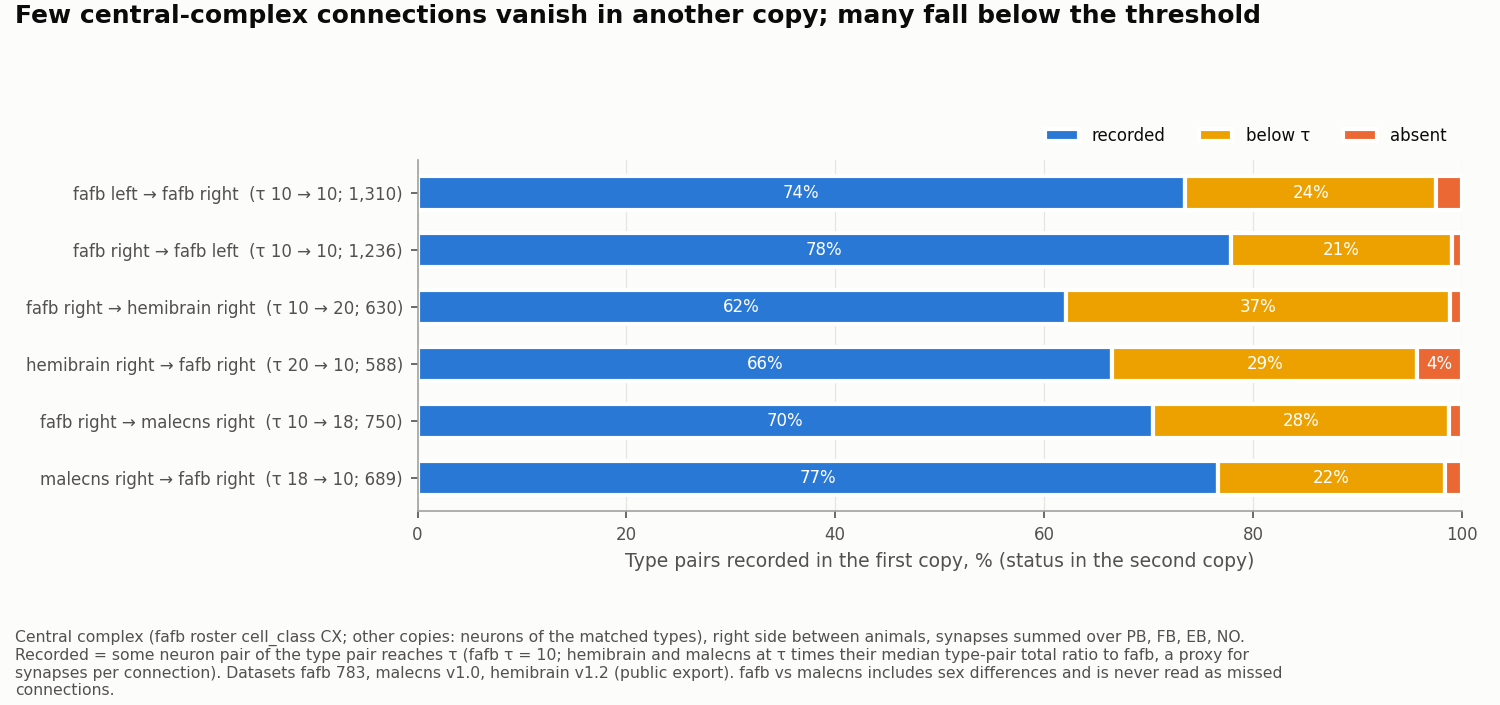

In [9]:
from src.discrepancy import fafb_left_right, fafb_vs_other, fig_discrepancy
from IPython.display import Image, display
lr, lr_info = fafb_left_right(neurons, edgeroi)
hb, hb_info = fafb_vs_other(neurons, edgeroi, hemi[0], hemi[2], 'hemibrain_type', 'cell_type', 'hemibrain')
mc, mc_info = fafb_vs_other(neurons, edgeroi, mal[0], mal[2], 'cell_type', 'flywire_type', 'malecns')
print({'fafb left vs right': lr_info, 'fafb vs hemibrain': hb_info, 'fafb vs malecns': mc_info})
table = pd.concat({'fafb L/R': lr, 'fafb/hemibrain': hb, 'fafb/malecns': mc}, names=['comparison']).reset_index(level=0)
(ROOT / 'reports').mkdir(exist_ok=True)
table.to_csv(ROOT / 'reports' / 'step15_discrepancy.csv', index=False)
display(table[table.tau == 10].round(3))
display(Image(filename=str(fig_discrepancy({'lr': lr, 'hb': hb, 'mc': mc}))))

## What this shows

Counts match the course checks for both datasets (fafb 2,700,513 and malecns 6,235,649 edges at 5 synapses), and the cache works offline. The central complex gives 32,125 positives at τ = 10. Few central-complex connections recorded at τ vanish entirely in another copy (1–4% of type pairs), but many fall below the threshold (21–24% within fafb; 29–37% against the hemibrain even after scaling its threshold by the type-pair total ratio of 2.0). See `reports/step15_discrepancy.md`.